# F1 lap-time prediction across the 2026 regulation change
## Notebook 01 - data acquisition and validation

**Question:** does a lap-time model trained on 2022-2025 still work on 2026 cars, and how many 2026 races does it need to recover?

This notebook downloads the data, checks that it's fit for modelling (quantity, quality, a well-defined target), runs the cleaning funnel and builds the target. It writes `data/clean_laps.csv.gz`, which every later notebook starts from.

**Data source:** the [TracingInsights](https://github.com/TracingInsights) season repositories, which publish [FastF1](https://github.com/theOehrly/Fast-F1)-derived lap tables (lap time, tyre, stint, track status, pit flags and weather joined per lap) for every session. The download, cleaning and target logic all live in `src/f1lap/` so there's one source of truth for the rules.

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1lap.download import download_all
from f1lap.clean import load_raw, clean_laps, add_target

pd.set_option('future.no_silent_downcasting', True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEASONS = [2022, 2023, 2024, 2025, 2026]
os.makedirs('figures', exist_ok=True); os.makedirs('data', exist_ok=True)

### 1. Download
Each season repo also holds GBs of telemetry and team radio, so we sparse-checkout only the lap tables we need. This is a no-op once the data is present.

In [2]:
download_all(SEASONS)

### 2. Load into one table (one row per driver-lap)

In [3]:
raw = load_raw(SEASONS)
raw.shape

(124920, 18)

### 3. Validate quantity, quality and the target

In [4]:
qty = raw.groupby('season').agg(races=('event', 'nunique'), laps=('lap_time_s', 'size'),
                                drivers=('driver', 'nunique'), teams=('team', 'nunique'))
qty

,races,laps,drivers,teams
season,,,,
2022,22,23577,22,10
2023,22,24422,22,10
2024,24,26606,24,10
2025,24,26692,21,10
2026,20,23623,25,11


**Quantity.** Every season has 20-24 races and roughly 23-27k driver-laps, so 2026 is not a small afterthought; it's about as big as any earlier season. 2026 has 11 teams (Cadillac joins) and 25 drivers because of mid-season driver changes.

In [5]:
miss = (raw.drop(columns=['pit_in', 'pit_out']).isna().mean() * 100).round(2).sort_values(ascending=False)
miss[miss > 0].to_frame('% missing')

,% missing
tyre_age,1.11
compound,0.77
stint,0.36
lap_time_s,0.24
position,0.17
deleted,0.03


**Quality.** Every modelling column is under ~1.1% missing. `pit_in` / `pit_out` are left out of this table on purpose: they're ~96% empty by design because they're only filled on the lap a car enters or leaves the pits, so we treat them as flags rather than missing data. Missing lap times come from crashes, retirements and red flags; there's no sensible way to impute a lap that wasn't driven, and we have plenty of data, so those laps are simply dropped by the funnel below.

In [6]:
print(raw.compound.value_counts(dropna=False))
print('\nLap time (s) summary:'); print(raw.lap_time_s.describe().round(2))

compound
HARD            53169
MEDIUM          44292
SOFT            19440
INTERMEDIATE     6602
NaN               956
WET               461
Name: count, dtype: int64

Lap time (s) summary:
count    124619.00
mean         96.29
std          84.38
min          67.01
25%          81.66
50%          90.36
75%          99.69
max        3204.16
Name: lap_time_s, dtype: float64


**Target sanity.** The median lap is ~90 s, but the max is over 3,000 s, which is a lap that spans a red-flag stoppage. That long tail is exactly why we can't model raw laps directly: we need to strip out pit laps, safety cars and incidents first. About 6% of laps are on intermediate or wet tyres, which is a different problem (rain pace), so wet races are removed too.

### 4. Pre-processing: keep clean, representative green-flag laps
The funnel lives in `f1lap.clean.clean_laps`: recorded lap time -> not lap 1 -> no pit in/out -> green flag -> not deleted & accurate -> dry race + dry compound -> no rainfall & tyre age known -> within 107% of the stint median. A race counts as wet if more than 5% of its laps are on intermediate or wet tyres.

In [7]:
df, funnel, wet_races = clean_laps(raw)
print(f'Wet races removed: {len(wet_races)}:', sorted(f'{y} {e}' for y, e in wet_races))
held = raw.groupby('season').event.nunique(); usable = df.groupby('season').event.nunique()
print(pd.DataFrame({'races held': held, 'dry races kept': usable}).T.to_string())
funnel

Wet races removed: 14: ['2022 Emilia Romagna Grand Prix', '2022 Japanese Grand Prix', '2022 Monaco Grand Prix', '2022 Singapore Grand Prix', '2023 Dutch Grand Prix', '2023 Monaco Grand Prix', '2024 British Grand Prix', '2024 Canadian Grand Prix', '2024 São Paulo Grand Prix', '2025 Australian Grand Prix', '2025 Belgian Grand Prix', '2025 British Grand Prix', '2026 Bahrain Grand Prix', '2026 São Paulo Grand Prix']
season          2022  2023  2024  2025  2026
races held        22    22    24    24    20
dry races kept    18    20    21    21    18


,step,laps,% kept
0,All laps,124920,100.0
1,Lap time recorded,124619,99.8
2,Not lap 1,122422,98.0
3,No pit in/out lap,114293,91.5
4,Green flag only,103894,83.2
5,"Not deleted, accurate",102369,81.9
6,"Dry races, dry compounds",90551,72.5
7,"No rainfall on lap, tyre age known",89837,71.9
8,Within 107% of stint median,89737,71.8


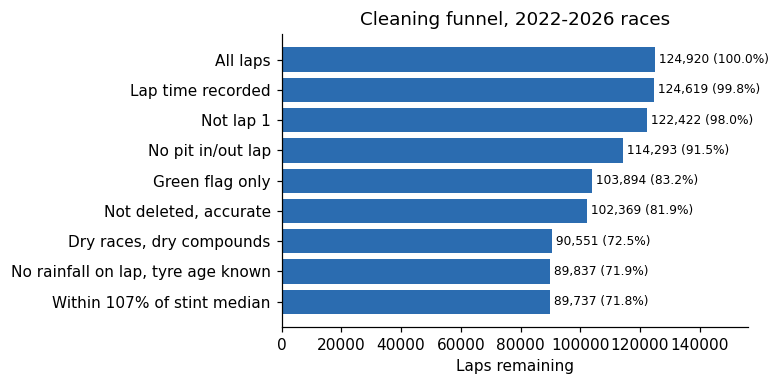

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(funnel.step[::-1], funnel.laps[::-1], color='#2b6cb0')
for i, (n, p) in enumerate(zip(funnel.laps[::-1], funnel['% kept'][::-1])):
    ax.text(n, i, f' {n:,} ({p}%)', va='center', fontsize=8)
ax.set_xlabel('Laps remaining'); ax.set_title('Cleaning funnel, 2022-2026 races'); ax.set_xlim(0, funnel.laps.max() * 1.25)
plt.tight_layout(); plt.savefig('figures/01_funnel.png', dpi=150); plt.show()

**Figure 01.** We keep about 72% of laps. The three biggest cuts are whole wet races (~11.8k laps), non-green-flag laps (safety cars, VSCs, yellow flags, ~10.4k) and pit in/out laps (~8.1k), which are all laps where the lap time is dominated by something other than the car's normal pace. The final 107% outlier filter barely removes anything (~100 laps), which tells us the earlier steps already caught almost all the weird laps, so the threshold choice isn't driving our results.

### 5. Target: lap-time delta to the race median
Raw lap times differ massively by circuit (a ~70 s Red Bull Ring lap vs a ~105 s Silverstone lap), so we subtract each race's median clean lap time. The model then learns pace *within* a race instead of memorising track length.

In [9]:
df = add_target(df)
df.groupby('season').lap_delta_s.describe().round(3)

,count,mean,std,min,25%,50%,75%,max
season,,,,,,,,
2022,15140.0,-0.034,1.286,-4.991,-0.879,0.0,0.784,6.508
2023,17788.0,0.054,1.227,-4.402,-0.752,0.0,0.805,24.170
2024,20156.0,0.008,1.291,-5.272,-0.894,0.0,0.865,6.333
2025,20131.0,0.028,1.226,-5.292,-0.805,0.0,0.852,8.985
2026,16522.0,0.164,1.607,-5.243,-0.940,0.0,1.139,10.768


**Target.** The delta has a median of exactly 0 in every season by construction, and its spread is stable at ~1.23-1.29 s (std) for 2022-2025 but jumps to ~1.6 s in 2026, about 25% wider. That's our first evidence that the regulation change actually changed the data, before any model is trained. Notebook 02 digs into it visually.

### 6. Save the clean table

In [10]:
df.to_csv('data/clean_laps.csv.gz', index=False)
print('Saved data/clean_laps.csv.gz', df.shape)

Saved data/clean_laps.csv.gz (89737, 20)
